In [ ]:
#Understanding Product Categories

#Frequency Analysis

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('raw_data/amz_uk_price_prediction_dataset.csv')  # Assuming the file is named this way

# Generate frequency table
category_counts = df['category'].value_counts()

# Top 5 categories
top_5_categories = category_counts.head(5)
print("Top 5 most listed product categories:")
print(top_5_categories)

Top 5 most listed product categories:
category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


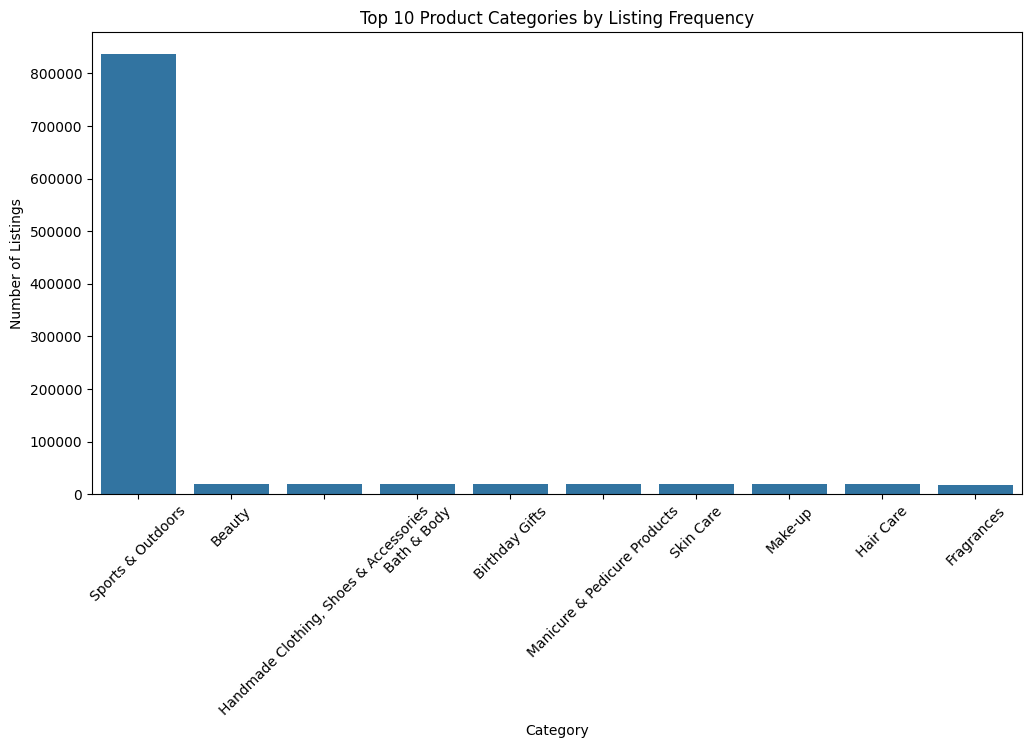

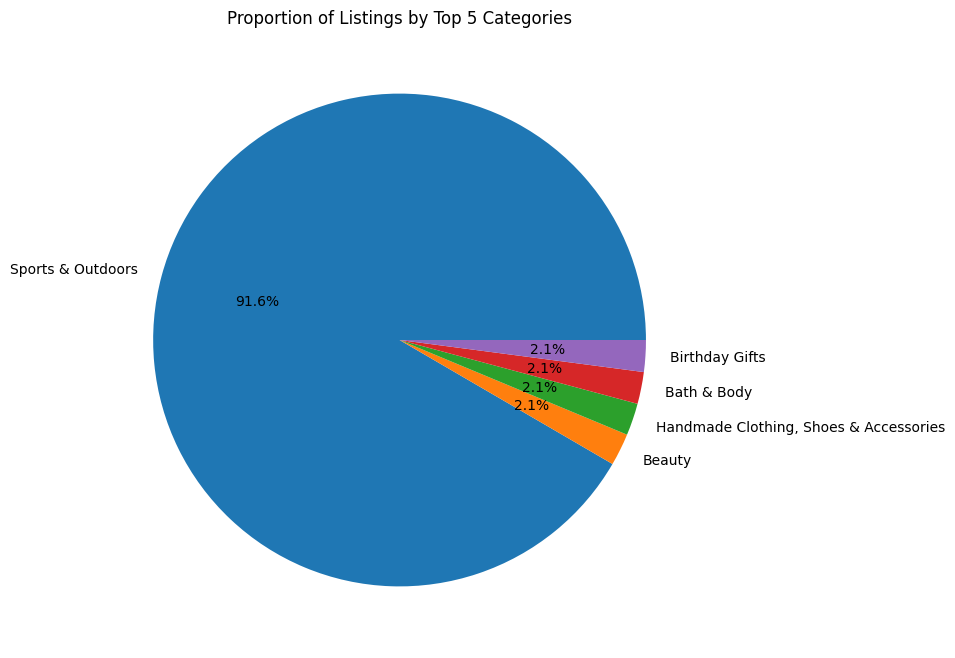

In [ ]:
#Visualizations

# Bar chart for top categories
plt.figure(figsize=(12,6))
top_10_categories = category_counts.head(10)
sns.barplot(x=top_10_categories.index, y=top_10_categories.values)
plt.title('Top 10 Product Categories by Listing Frequency')
plt.xlabel('Category')
plt.ylabel('Number of Listings')
plt.xticks(rotation=45)
plt.show()

# Pie chart for top 5 categories
plt.figure(figsize=(8,8))
plt.pie(top_5_categories, labels=top_5_categories.index, autopct='%1.1f%%')
plt.title('Proportion of Listings by Top 5 Categories')
plt.show()

In [ ]:
#Central Tendency Measures

# Just ensure it's float
df['price'] = df['price'].astype(float)

# Calculate metrics
price_mean = df['price'].mean()
price_median = df['price'].median()
price_mode = df['price'].mode()[0]

print(f"Mean price: £{price_mean:.2f}")
print(f"Median price: £{price_median:.2f}")
print(f"Mode price: £{price_mode:.2f}")

Mean price: £89.24
Median price: £19.09
Mode price: £9.99


In [ ]:
#Dispersion Measures

price_var = df['price'].var()
price_std = df['price'].std()
price_range = df['price'].max() - df['price'].min()
price_iqr = df['price'].quantile(0.75) - df['price'].quantile(0.25)

print(f"Variance: {price_var:.2f}")
print(f"Standard Deviation: {price_std:.2f}")
print(f"Range: £{price_range:.2f}")
print(f"IQR: £{price_iqr:.2f}")

Variance: 119445.49
Standard Deviation: 345.61
Range: £100000.00
IQR: £36.00


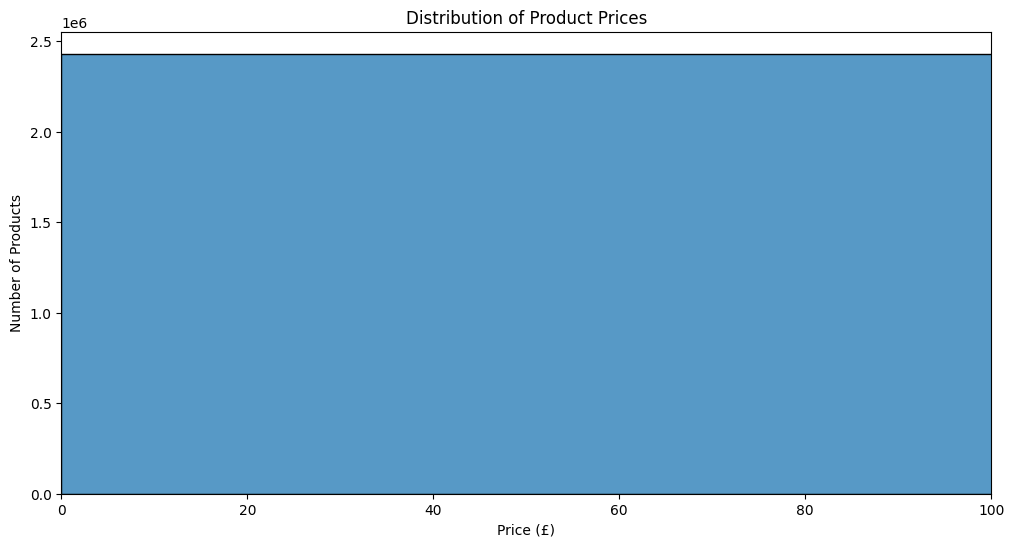

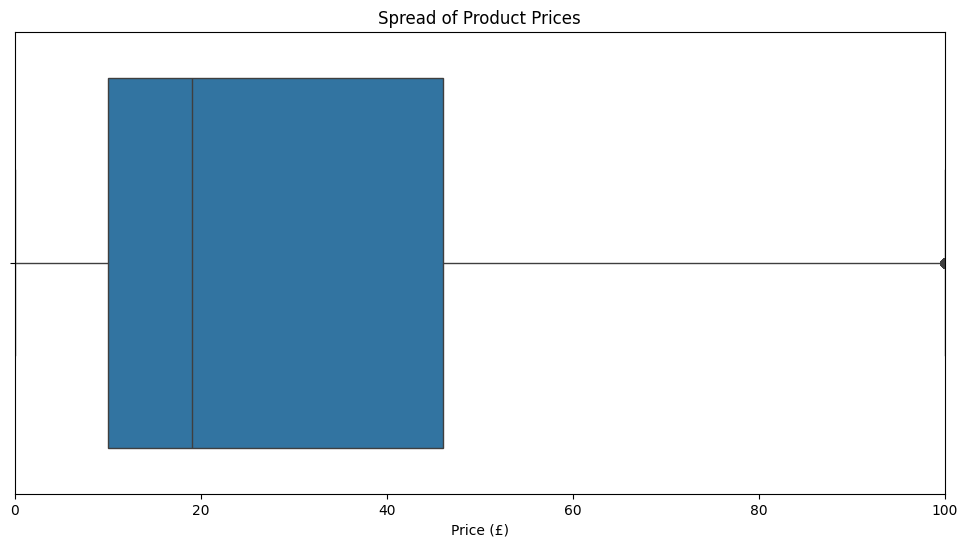

In [ ]:
# Visualizations

# Histogram
plt.figure(figsize=(12,6))
sns.histplot(df['price'], bins=50)
plt.title('Distribution of Product Prices')
plt.xlabel('Price (£)')
plt.ylabel('Number of Products')
plt.xlim(0, 100)  # Adjust based on your data
plt.show()

# Box plot
plt.figure(figsize=(12,6))
sns.boxplot(x=df['price'])
plt.title('Spread of Product Prices')
plt.xlabel('Price (£)')
plt.xlim(0, 100)  # Adjust based on your data
plt.show()

Missing values in 'stars': 0

Rating Analysis (Stars):
Mean stars: 2.15
Median stars: 0.00
Most common rating (mode): 0.00

Standard Deviation: 2.19
IQR: 4.40

Skewness: 0.08
Kurtosis: -1.93


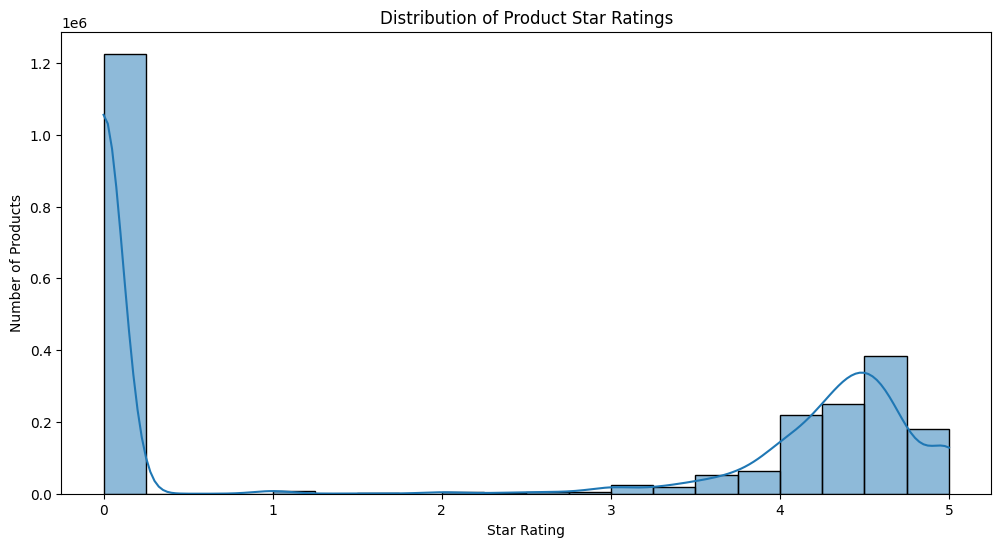

In [ ]:
#Part 3: Unpacking Product Ratings (Now Using 'stars')

# Check for missing values in stars
print("Missing values in 'stars':", df['stars'].isnull().sum())

# Convert stars to numeric (in case it's stored as text)
df['stars'] = pd.to_numeric(df['stars'], errors='coerce')

# Measures of Centrality
stars_mean = df['stars'].mean()
stars_median = df['stars'].median()
stars_mode = df['stars'].mode()[0]

print(f"\nRating Analysis (Stars):")
print(f"Mean stars: {stars_mean:.2f}")
print(f"Median stars: {stars_median:.2f}")
print(f"Most common rating (mode): {stars_mode:.2f}")

# Measures of Dispersion
stars_std = df['stars'].std()
stars_iqr = df['stars'].quantile(0.75) - df['stars'].quantile(0.25)

print(f"\nStandard Deviation: {stars_std:.2f}")
print(f"IQR: {stars_iqr:.2f}")

# Shape of Distribution
from scipy.stats import skew, kurtosis
stars_skew = skew(df['stars'].dropna())
stars_kurt = kurtosis(df['stars'].dropna())

print(f"\nSkewness: {stars_skew:.2f}")
print(f"Kurtosis: {stars_kurt:.2f}")

# Visualizations
plt.figure(figsize=(12,6))
sns.histplot(df['stars'].dropna(), bins=20, kde=True)
plt.title('Distribution of Product Star Ratings')
plt.xlabel('Star Rating')
plt.ylabel('Number of Products')
plt.show()

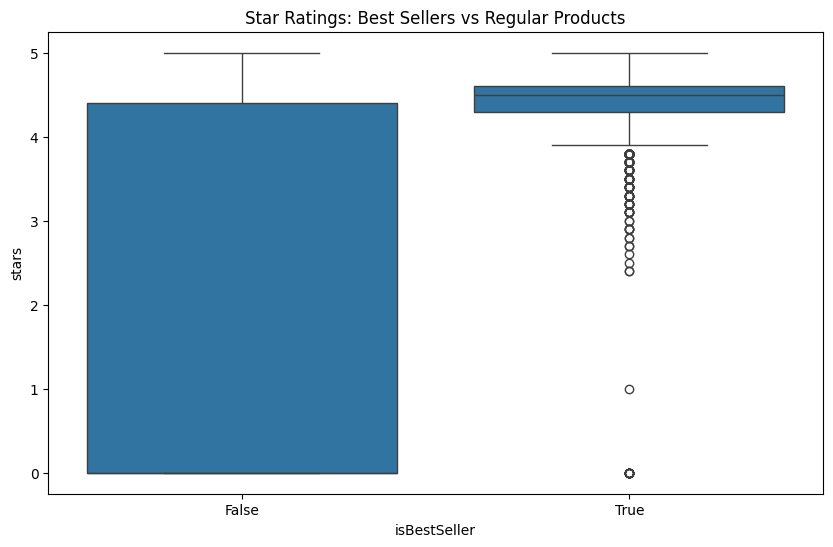

In [ ]:
#Best Sellers Analysis (Using 'isBestSeller')

# Best seller vs rating comparison
if 'isBestSeller' in df.columns:
    plt.figure(figsize=(10,6))
    sns.boxplot(x='isBestSeller', y='stars', data=df)
    plt.title('Star Ratings: Best Sellers vs Regular Products')
    plt.show()

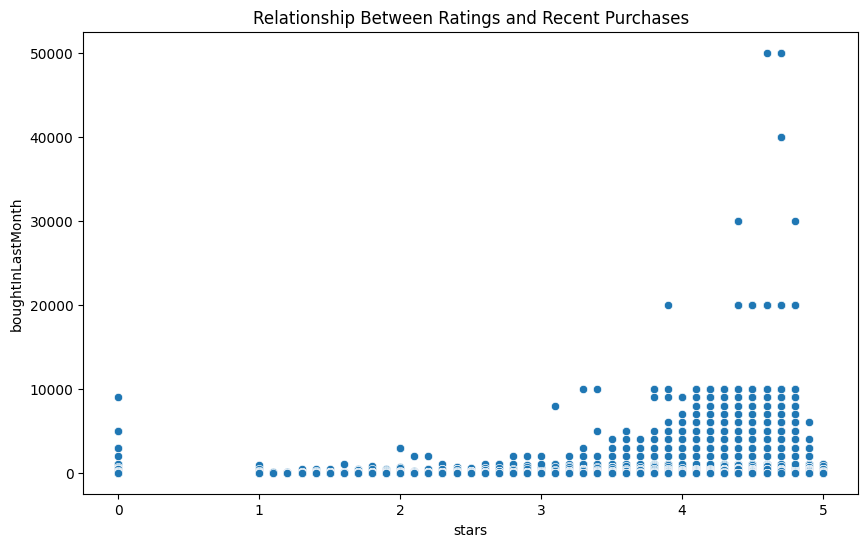

In [ ]:
#Purchase Activity Analysis (Using 'boughtInLastMonth')

# Relationship between recent purchases and ratings
if 'boughtInLastMonth' in df.columns:
    plt.figure(figsize=(10,6))
    sns.scatterplot(x='stars', y='boughtInLastMonth', data=df)
    plt.title('Relationship Between Ratings and Recent Purchases')
    plt.show()

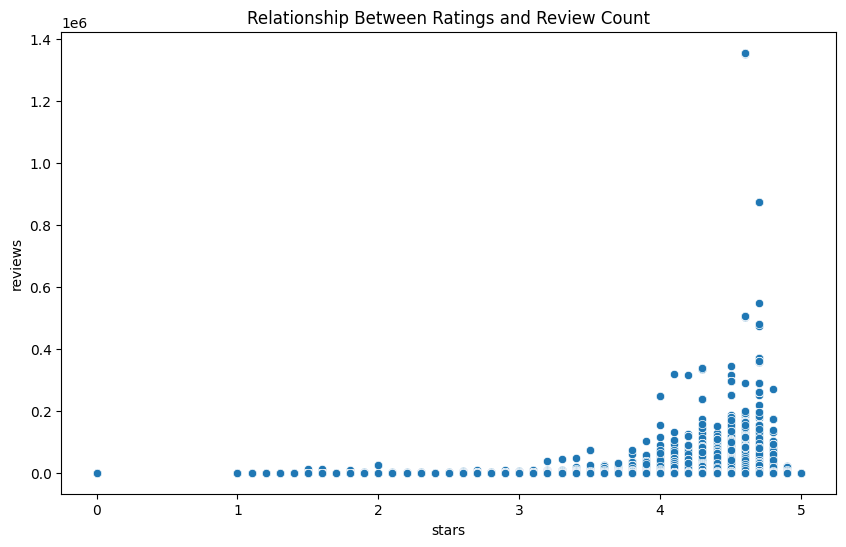

In [ ]:
#Review Count Analysis (Using 'reviews')

# Relationship between number of reviews and ratings
if 'reviews' in df.columns:
    plt.figure(figsize=(10,6))
    sns.scatterplot(x='stars', y='reviews', data=df)
    plt.title('Relationship Between Ratings and Review Count')
    plt.show()